# Full-Run Model Benchmark Comparison and Reliability Analysis

This notebook analyses the saved **full experiments** used by ModelLens, covering:
- **Gemma 3 4B**
- **Llama 3.2 1B**
- **Llama 3.2 3B**
- **Phi-4 Mini 3.8B**

Qwen 2.5 7B is excluded because this repository contains only its pilot results. Pilot, smoke and local evaluator runs are not mixed into these comparisons.

It reads saved `results/` through `llm_fact_checker.results`, without invoking models, downloading data or writing result files. Run the cells in order using the repository's notebook environment. Missing scores are N/A, not zero.

Here, “full” means the project's complete eligible benchmark populations, not every record in the original datasets: 13,332 FEVER claims and 20,232 valid VitaminC pairs. These experiments evaluate supplied-evidence verdicts, not general-purpose model quality.

## 1. Setup & Results Discovery

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from llm_fact_checker.results import discover_runs, select

full_experiments = {'baseline_full', 'consistency_5run_full', 'robustness_full', 'sensitivity_full'}
runs = [run for run in discover_runs() if run.experiment in full_experiments]
assert runs, 'No saved full-run results found.'
# Check the recorded dataset and sampling settings agree within each test.
for kind in ('baseline', 'consistency', 'robustness', 'sensitivity'):
    selected = select(runs, kind=kind)
    signatures = {(r.provenance()['dataset_sha256'], r.provenance()['temperature'],
                   tuple(r.provenance()['seeds'] or [])) for r in selected}
    assert len(signatures) <= 1, f'Incompatible full-run settings for {kind}.'
    assert all(r.provenance()['dataset_sha256'] for r in selected), 'Missing dataset fingerprint.'
print(f"Discovered {len(runs)} saved full experiment runs across {len({r.model for r in runs})} models. Pilot, smoke and local runs are excluded.")

Discovered 16 saved full experiment runs across 4 models. Pilot, smoke and local runs are excluded.


## 2. Comparative Evaluation Scorecard

We report four separate dimensions, without combining them into an overall score:
1. **Correctness:** 13,332 FEVER claims, balanced across 6,666 SUPPORTS and 6,666 REFUTES gold labels.
2. **Consistency:** the same 13,332 claims and evidence, repeated five times at temperature 0.2 with seeds 101, 202, 303, 404 and 505.
3. **Robustness:** distractors on 13,332 claims; reordering on 1,204 eligible multi-sentence cases.
4. **Sensitivity:** 20,232 VitaminC pairs, requiring both evidence versions to be answered correctly.

Consistency and unchanged verdicts measure stability, not correctness. Invariance uses complete eligible pairs, so invalid/missing answers can reduce its denominator. Accuracy and sensitivity retain their saved scoring denominators. There are no gold NEI cases; an NEI prediction is not a correct answer on these populations.

The dataset fingerprints, temperatures and seeds are checked above. Runtime versions and source revisions differ between some recorded runs, so these are benchmark observations rather than a fully controlled comparison of model architecture alone.

In [2]:
models = sorted({r.model for r in runs})

scorecard_data = []
for m in models:
    b = [r for r in select(runs, model=m, kind='baseline') if r.experiment == 'baseline_full']
    c = [r for r in select(runs, model=m, kind='consistency') if r.experiment == 'consistency_5run_full']
    r_list = [r for r in select(runs, model=m, kind='robustness') if r.experiment == 'robustness_full']
    s = [r for r in select(runs, model=m, kind='sensitivity') if r.experiment == 'sensitivity_full']
    
    b_head = b[0].headline() if b else {}
    c_head = c[0].headline() if c else {}
    r_head = r_list[0].headline() if r_list else {}
    distractor = r_list[0].metrics()['distractor'] if r_list else {}
    s_head = s[0].headline() if s else {}
    
    scorecard_data.append({
        'Model': m,
        'FEVER Accuracy': b_head.get('accuracy'),
        'SUPPORTED Accuracy': b_head.get('supported_accuracy'),
        'REFUTED Accuracy': b_head.get('refuted_accuracy'),
        'NEI Rate': b_head.get('nei_rate'),
        '5/5 Consistency': c_head.get('exact_consistency'),
        'Reorder Invariance': r_head.get('reorder_invariance'),
        'Distractor Invariance': r_head.get('distractor_invariance'),
        'Distractor Control Acc': distractor.get('control_accuracy'),
        'Post-Distractor Acc': distractor.get('perturbed_accuracy'),
        'VitaminC Sensitivity': s_head.get('correct_sensitivity'),
    })

assert scorecard_data, 'No saved full-run results found.'
df_scorecard = pd.DataFrame(scorecard_data)
score_columns = [column for column in df_scorecard if column != 'Model']
df_scorecard[score_columns] = df_scorecard[score_columns].astype(float)
display(df_scorecard.style.format({column: '{:.1%}' for column in score_columns}, na_rep='N/A'))

,Model,FEVER Accuracy,SUPPORTED Accuracy,REFUTED Accuracy,NEI Rate,5/5 Consistency,Reorder Invariance,Distractor Invariance,Distractor Control Acc,Post-Distractor Acc,VitaminC Sensitivity
0,gemma3_4b,78.4%,94.1%,62.8%,6.7%,99.6%,83.5%,82.8%,78.4%,72.9%,48.8%
1,llama3.2_1b,48.5%,95.0%,2.0%,10.7%,75.1%,94.9%,84.1%,48.5%,45.4%,0.4%
2,llama3.2_3b,70.3%,80.7%,59.8%,15.9%,78.4%,79.6%,30.9%,70.3%,17.6%,30.9%
3,phi4-mini_3.8b,59.9%,96.4%,23.3%,19.3%,90.9%,86.1%,58.4%,59.9%,33.4%,17.3%


## 3. Full-Run Metric Comparisons

The distractor panel uses original and perturbed accuracy from the same robustness experiment and eligible population. Missing values have no bar; refer to N/A in the table rather than interpreting absence as zero.

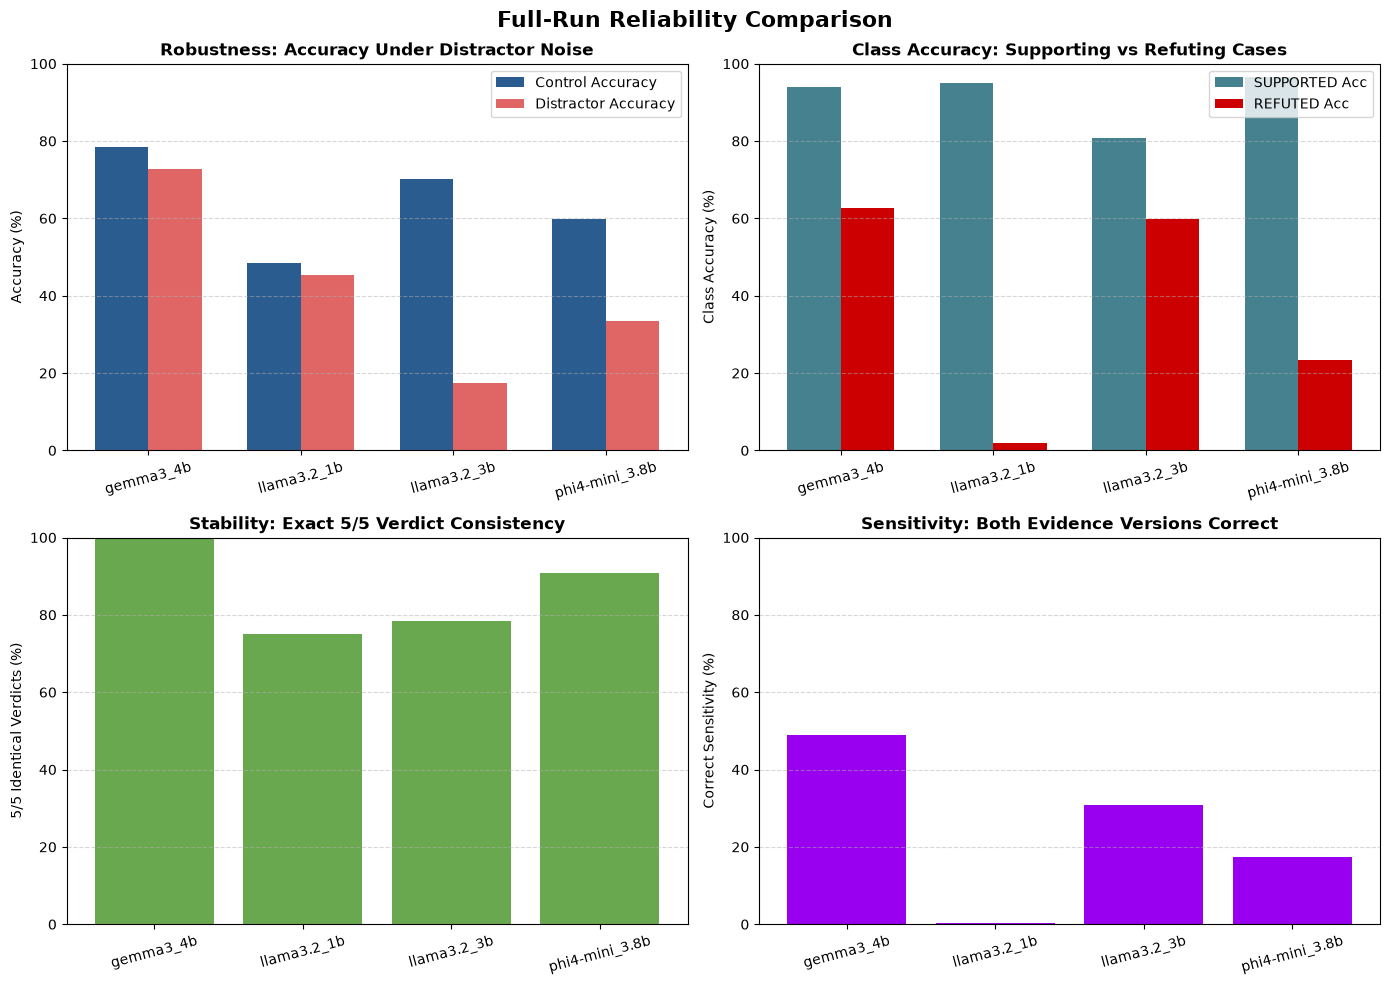

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Full-Run Reliability Comparison", fontsize=16, fontweight='bold')

# 1. Accuracy vs Post-Distractor Accuracy
x = range(len(df_scorecard))
width = 0.35
axes[0, 0].bar([i - width/2 for i in x], df_scorecard['Distractor Control Acc'] * 100, width, label='Control Accuracy', color='#2b5c8f')
axes[0, 0].bar([i + width/2 for i in x], df_scorecard['Post-Distractor Acc'] * 100, width, label='Distractor Accuracy', color='#e06666')
axes[0, 0].set_title("Robustness: Accuracy Under Distractor Noise", fontweight='bold')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(df_scorecard['Model'], rotation=15)
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].set_ylim(0, 100)
axes[0, 0].legend()
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Polarity Discrimination (SUPPORTED vs REFUTED)
axes[0, 1].bar([i - width/2 for i in x], df_scorecard['SUPPORTED Accuracy'] * 100, width, label='SUPPORTED Acc', color='#45818e')
axes[0, 1].bar([i + width/2 for i in x], df_scorecard['REFUTED Accuracy'] * 100, width, label='REFUTED Acc', color='#cc0000')
axes[0, 1].set_title("Class Accuracy: Supporting vs Refuting Cases", fontweight='bold')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(df_scorecard['Model'], rotation=15)
axes[0, 1].set_ylabel("Class Accuracy (%)")
axes[0, 1].set_ylim(0, 100)
axes[0, 1].legend()
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.5)

# 3. Repeat-Run Stability (5/5 Consistency)
axes[1, 0].bar(df_scorecard['Model'], df_scorecard['5/5 Consistency'] * 100, color='#6aa84f')
axes[1, 0].set_title("Stability: Exact 5/5 Verdict Consistency", fontweight='bold')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(df_scorecard['Model'], rotation=15)
axes[1, 0].set_ylabel("5/5 Identical Verdicts (%)")
axes[1, 0].set_ylim(0, 100)
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.5)

# 4. VitaminC Contrastive Sensitivity
axes[1, 1].bar(df_scorecard['Model'], df_scorecard['VitaminC Sensitivity'] * 100, color='#9900ef')
axes[1, 1].set_title("Sensitivity: Both Evidence Versions Correct", fontweight='bold')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(df_scorecard['Model'], rotation=15)
axes[1, 1].set_ylabel("Correct Sensitivity (%)")
axes[1, 1].set_ylim(0, 100)
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 4. Error Analysis and Disagreement Case Studies

Here we inspect full-run FEVER cases where Gemma 3 4B and Phi-4 Mini 3.8B returned different parsed verdicts. Both models were evaluated on the same recorded claims and evidence. Disagreement alone does not identify which model is correct. Inspect the gold label and evidence before explaining a failure.

This optional analysis requires both full baseline prediction files. Large prediction files are not necessarily included in the checkout; if either is absent, this section reports that limitation without substituting pilot data. The aggregate scorecard and charts above still use the saved full metrics. When available, the table shows the first ten disagreements in saved-record order, not a representative random sample.

In [4]:
# Discovery above restricts both selections to the full experiments.
b_gemma = select(runs, model='gemma3_4b', kind='baseline')
b_phi = select(runs, model='phi4-mini_3.8b', kind='baseline')

prediction_files_available = b_gemma and b_phi and all(
    (run.path / 'predictions.jsonl').is_file() for run in (b_gemma[0], b_phi[0]))
if prediction_files_available:
    cases_gemma = {c['fever_id']: c for c in b_gemma[0].cases()}
    cases_phi = {c['fever_id']: c for c in b_phi[0].cases()}
    assert len(cases_gemma) == b_gemma[0].headline()['cases']
    assert len(cases_phi) == b_phi[0].headline()['cases']
    assert cases_gemma.keys() == cases_phi.keys(), 'Full-run case IDs differ.'
    assert all(cases_gemma[fid][key] == case[key] for fid, case in cases_phi.items()
               for key in ('claim', 'evidence', 'gold_label')), 'Full-run inputs differ.'
    
    disagreements = []
    for fid, c_phi in cases_phi.items():
        c_gemma = cases_gemma.get(fid)
        if c_gemma and c_phi['parsed_prediction'] != c_gemma['parsed_prediction']:
            disagreements.append({
                'fever_id': fid,
                'claim': c_phi['claim'],
                'evidence': c_phi['evidence'],
                'gold_label': c_phi['gold_label'],
                'gemma3_4b': c_gemma['parsed_prediction'],
                'phi4-mini_3.8b': c_phi['parsed_prediction'],
            })
    
    df_disagree = pd.DataFrame(disagreements)
    print(f"Different parsed verdicts: {len(df_disagree)} / {len(cases_phi)} matched full-run claims")
    display(df_disagree.head(10))
else:
    print("Case-level comparison unavailable: both Gemma and Phi full baseline metrics and predictions.jsonl files are required. No pilot data has been substituted.")

Case-level comparison unavailable: both Gemma and Phi full baseline metrics and predictions.jsonl files are required. No pilot data has been substituted.


## 5. Interpretation of the Saved Full Results

These observations describe the current four-model full-run records, not pilot or local-demo results. Revisit this summary if those records change.

1. **Correctness:** Gemma has the highest observed accuracy at **78.4%**, followed by Llama 3.2 3B (**70.3%**), Phi-4 Mini (**59.9%**) and Llama 3.2 1B (**48.5%**). This ranks accuracy on this benchmark, not overall model quality.

2. **Class-level performance explains differences:** Gemma achieves **94.1%** on supporting cases and **62.8%** on refuting cases. Phi-4 Mini is slightly higher on supporting cases (**96.4%**) but much lower on refuting cases (**23.3%**). An engineer should inspect refuting-case errors rather than relying only on overall accuracy. These scores do not establish the cause of the errors.

3. **Consistency is not correctness:** Gemma has **99.6%** exact five-run consistency, but **2,842/13,332 claims (21.3%)** are consistently wrong. Phi-4 Mini has **90.9%** consistency, Llama 3.2 3B **78.4%**, and Llama 3.2 1B **75.1%**. Repeated agreement is useful only alongside correctness and incomplete-response counts.

4. **Robustness needs both accuracy and stability:** with distractors, Llama 3.2 3B falls from **70.3% to 17.6%**, a **52.7 percentage-point decrease**. Gemma falls from **78.4% to 72.9%**, a **5.5 percentage-point decrease**. Llama 3.2 1B has a smaller accuracy decrease (**3.1 percentage points**) but starts at only **48.5%**. Its high reorder invariance (**94.9%**) also does not mean its answers are correct.

5. **Sensitivity requires correct adaptation:** both-evidence-correct rates are **48.8%** for Gemma, **30.9%** for Llama 3.2 3B, **17.3%** for Phi-4 Mini and **0.4%** for Llama 3.2 1B. A changed verdict alone is not success. Even the highest score leaves substantial room for improvement on paired evidence revisions.

**Limits:** results apply to these eligible FEVER and VitaminC populations, prompts and recorded settings. There are no gold NEI cases. Scores do not establish statistical significance, state-of-the-art performance or suitability for private banking/legal data. Inspect saved configurations and case-level errors before making deployment decisions.